# Research Thesis Practicum Notebook

## A Comparative Analysis of Machine Learning Models for Predicting Homelessness Pressure in Ireland

This notebook contains the full practical workflow:

1. Merge CSV files
2. Load and clean data
3. Extract date information
4. Create High/Low homelessness-pressure target
5. Feature engineering
6. Train and compare ML models
7. Evaluate best model
8. Use SHAP and optional LIME explainability

In [1]:
pip install lime

In [1]:
# Imports and output folder setup

import os, re, glob, warnings, time
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay, RocCurveDisplay
)
from sklearn.model_selection import TimeSeriesSplit, cross_val_score

RANDOM_STATE = 42

# Folder used to save charts/images generated by the notebook.
OUTPUT_DIR = "outputs"
IMAGE_DIR = os.path.join(OUTPUT_DIR, "images")
os.makedirs(IMAGE_DIR, exist_ok=True)

try:
    from xgboost import XGBClassifier
    XGBOOST_AVAILABLE = True
except Exception:
    XGBOOST_AVAILABLE = False
    print("XGBoost not installed. Use: pip install xgboost")

try:
    import shap
    SHAP_AVAILABLE = True
except Exception:
    SHAP_AVAILABLE = False
    print("SHAP not installed. Use: pip install shap")

try:
    from lime.lime_tabular import LimeTabularExplainer
    LIME_AVAILABLE = True
except Exception:
    LIME_AVAILABLE = False
    print("LIME not installed. Use: pip install lime")

print("Imports completed")
print("XGBoost:", XGBOOST_AVAILABLE, "| SHAP:", SHAP_AVAILABLE, "| LIME:", LIME_AVAILABLE)
print("Images will be saved in:", IMAGE_DIR)

# Start total notebook timer
notebook_start_time = time.time()


Imports completed
XGBoost: True | SHAP: True | LIME: True
Images will be saved in: outputs\images


In [2]:
# Merge raw CSV files

DATA_FOLDER = r"C:\Users\ADMIN\homelessness_data" 

csv_files = glob.glob(os.path.join(DATA_FOLDER, "*.csv"))
csv_files = [f for f in csv_files if os.path.basename(f).lower() != "merged_homelessness_2019_2025.csv"]

print("Raw CSV files found:", len(csv_files))

if len(csv_files) > 0:
    frames = []
    for file in csv_files:
        temp = pd.read_csv(file)
        temp["source_file"] = os.path.basename(file)
        frames.append(temp)

    merged_df = pd.concat(frames, ignore_index=True)
    merged_path = os.path.join(DATA_FOLDER, "merged_homelessness_2019_2025.csv")
    merged_df.to_csv(merged_path, index=False)

    print("Merged dataset saved:", merged_path)
    print("Merged shape:", merged_df.shape)
    display(merged_df.head())
else:
    print("No raw CSV files found. Continue if you already have merged CSV.")


Raw CSV files found: 57
Merged dataset saved: C:\Users\ADMIN\homelessness_data\merged_homelessness_2019_2025.csv
Merged shape: (513, 21)


,Region,Total Adults,Male Adults,Female Adults,Adults Aged 18-24,Adults Aged 25-44,Adults Aged 45-64,Adults Aged 65+,Number of people who accessed Private Emergency Accommodation,Number of people who accessed Supported Temporary Accommodation,...,Number of people who accessed Other Accommodation,Number of people with citizenship Irish,Number of people with citizenship EEA/Uk,Number of people with citizenship Non-EEA,Number of Families,Number of Adults in Families,Number of Single-Parent families,Number of Dependants in Families,source_file,Number of single adults
0,Dublin,"4,991","3,218","1,773",918,"2,666",1340,67,"2,884","2,117",...,0,2912,1227,852,956,1626,473.0,2209,homelessness-report-april-2022.csv,NaN
1,Mid-East,405,257,148,78,199,113,15,243,153,...,4,283,71,51,76,128,40.0,173,homelessness-report-april-2022.csv,NaN
2,Midlands,101,52,49,19,57,23,2,66,0,...,1,83,11,7,22,27,17.0,42,homelessness-report-april-2022.csv,NaN
3,Mid-West,341,212,129,43,189,97,12,76,233,...,0,284,41,16,57,78,42.0,109,homelessness-report-april-2022.csv,NaN
4,North-East,89,58,31,12,48,22,7,33,55,...,0,74,13,2,11,16,7.0,24,homelessness-report-april-2022.csv,NaN


In [4]:
# Load merged dataset

MERGED_CSV_PATH = r"C:\Users\ADMIN\homelessness_data\merged_homelessness_2019_2025.csv" 

if not os.path.exists(MERGED_CSV_PATH):
    raise FileNotFoundError("Merged CSV not found. Update MERGED_CSV_PATH.")

df = pd.read_csv(MERGED_CSV_PATH)

print("Dataset loaded")
print("Shape:", df.shape)
display(df.head())


Dataset loaded
Shape: (513, 21)


,Region,Total Adults,Male Adults,Female Adults,Adults Aged 18-24,Adults Aged 25-44,Adults Aged 45-64,Adults Aged 65+,Number of people who accessed Private Emergency Accommodation,Number of people who accessed Supported Temporary Accommodation,...,Number of people who accessed Other Accommodation,Number of people with citizenship Irish,Number of people with citizenship EEA/Uk,Number of people with citizenship Non-EEA,Number of Families,Number of Adults in Families,Number of Single-Parent families,Number of Dependants in Families,source_file,Number of single adults
0,Dublin,"4,991","3,218","1,773",918,"2,666",1340,67,"2,884","2,117",...,0,2912,1227,852,956,1626,473.0,2209,homelessness-report-april-2022.csv,NaN
1,Mid-East,405,257,148,78,199,113,15,243,153,...,4,283,71,51,76,128,40.0,173,homelessness-report-april-2022.csv,NaN
2,Midlands,101,52,49,19,57,23,2,66,0,...,1,83,11,7,22,27,17.0,42,homelessness-report-april-2022.csv,NaN
3,Mid-West,341,212,129,43,189,97,12,76,233,...,0,284,41,16,57,78,42.0,109,homelessness-report-april-2022.csv,NaN
4,North-East,89,58,31,12,48,22,7,33,55,...,0,74,13,2,11,16,7.0,24,homelessness-report-april-2022.csv,NaN


In [5]:
# Clean column names

df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
    .str.replace("-", "_", regex=False)
    .str.replace("/", "_", regex=False)
    .str.replace("(", "", regex=False)
    .str.replace(")", "", regex=False)
)

print(df.columns.tolist())


['region', 'total_adults', 'male_adults', 'female_adults', 'adults_aged_18_24', 'adults_aged_25_44', 'adults_aged_45_64', 'adults_aged_65+', 'number_of_people_who_accessed_private_emergency_accommodation', 'number_of_people_who_accessed_supported_temporary_accommodation', 'number_of_people_who_accessed_temporary_emergency_accommodation', 'number_of_people_who_accessed_other_accommodation', 'number_of_people_with_citizenship_irish', 'number_of_people_with_citizenship_eea_uk', 'number_of_people_with_citizenship_non_eea', 'number_of_families', 'number_of_adults_in_families', 'number_of_single_parent_families', 'number_of_dependants_in_families', 'source_file', 'number_of_single_adults']


In [6]:
# Select target count column

TARGET_COUNT_COL = "number_of_people_who_accessed_temporary_emergency_accommodation"

if TARGET_COUNT_COL not in df.columns:
    possible_cols = [c for c in df.columns if any(k in c for k in ["temporary", "emergency", "accommodation", "people"])]
    print("Possible target columns:", possible_cols)
    raise ValueError("Update TARGET_COUNT_COL with the correct column.")

df[TARGET_COUNT_COL] = pd.to_numeric(df[TARGET_COUNT_COL], errors="coerce")

display(df[[TARGET_COUNT_COL]].describe())


,number_of_people_who_accessed_temporary_emergency_accommodation
count,513.000000
mean,14.311891
std,16.228959
min,0.000000
25%,0.000000
50%,5.000000
75%,30.000000
max,72.000000


In [7]:
# Convert numeric columns

for col in df.columns:
    if col not in ["region", "source_file"] and df[col].dtype == "object":
        cleaned = df[col].astype(str).str.replace(",", "", regex=False).str.strip()
        df[col] = pd.to_numeric(cleaned, errors="ignore")

display(df.head())


,region,total_adults,male_adults,female_adults,adults_aged_18_24,adults_aged_25_44,adults_aged_45_64,adults_aged_65+,number_of_people_who_accessed_private_emergency_accommodation,number_of_people_who_accessed_supported_temporary_accommodation,...,number_of_people_who_accessed_other_accommodation,number_of_people_with_citizenship_irish,number_of_people_with_citizenship_eea_uk,number_of_people_with_citizenship_non_eea,number_of_families,number_of_adults_in_families,number_of_single_parent_families,number_of_dependants_in_families,source_file,number_of_single_adults
0,Dublin,4991,3218,1773,918,2666,1340,67,2884,2117,...,0,2912,1227,852,956,1626,473.0,2209,homelessness-report-april-2022.csv,NaN
1,Mid-East,405,257,148,78,199,113,15,243,153,...,4,283,71,51,76,128,40.0,173,homelessness-report-april-2022.csv,NaN
2,Midlands,101,52,49,19,57,23,2,66,0,...,1,83,11,7,22,27,17.0,42,homelessness-report-april-2022.csv,NaN
3,Mid-West,341,212,129,43,189,97,12,76,233,...,0,284,41,16,57,78,42.0,109,homelessness-report-april-2022.csv,NaN
4,North-East,89,58,31,12,48,22,7,33,55,...,0,74,13,2,11,16,7.0,24,homelessness-report-april-2022.csv,NaN


In [8]:
# Prepare date columns from source_file or existing year/month

def extract_year_month_from_filename(filename):
    filename = str(filename).lower()
    month_map = {
        "january": 1, "jan": 1, "february": 2, "feb": 2, "march": 3, "mar": 3,
        "april": 4, "apr": 4, "may": 5, "june": 6, "jun": 6, "july": 7, "jul": 7,
        "august": 8, "aug": 8, "september": 9, "sep": 9, "october": 10, "oct": 10,
        "november": 11, "nov": 11, "december": 12, "dec": 12
    }

    year_match = re.search(r"(20\d{2})", filename)
    year = int(year_match.group(1)) if year_match else np.nan

    month = np.nan
    for name, num in month_map.items():
        if name in filename:
            month = num
            break

    return pd.Series([year, month])

if "year" in df.columns and "month" in df.columns:
    df["year"] = pd.to_numeric(df["year"], errors="coerce")
    df["month"] = pd.to_numeric(df["month"], errors="coerce")
elif "source_file" in df.columns:
    print("Extracting year/month from source_file")
    df[["year", "month"]] = df["source_file"].apply(extract_year_month_from_filename)
else:
    raise ValueError("No year/month or source_file column found.")

df["date"] = pd.to_datetime(dict(year=df["year"], month=df["month"], day=1), errors="coerce")
df["time_index"] = df["year"] * 12 + df["month"]

REGION_COL = "region" if "region" in df.columns else None

df = df.dropna(subset=["date", "time_index", TARGET_COUNT_COL]).copy()
df = df.sort_values(["time_index"] + ([REGION_COL] if REGION_COL else [])).reset_index(drop=True)

print("Date range:", df["date"].min(), "to", df["date"].max())
print("Region column:", REGION_COL)
display(df.head())


Extracting year/month from source_file
Date range: 2019-01-01 00:00:00 to 2025-12-01 00:00:00
Region column: region


,region,total_adults,male_adults,female_adults,adults_aged_18_24,adults_aged_25_44,adults_aged_45_64,adults_aged_65+,number_of_people_who_accessed_private_emergency_accommodation,number_of_people_who_accessed_supported_temporary_accommodation,...,number_of_families,number_of_adults_in_families,number_of_single_parent_families,number_of_dependants_in_families,source_file,number_of_single_adults,year,month,date,time_index
0,Dublin,4258,2428,1830,577,2586,1018,77,2043,2242,...,1221,1708,734.0,2706,homelessness_report_january_2019.csv,NaN,2019,1,2019-01-01,24229
1,Mid-East,254,149,105,32,160,59,3,125,126,...,40,53,27.0,105,homelessness_report_january_2019.csv,NaN,2019,1,2019-01-01,24229
2,Mid-West,338,221,117,47,179,103,9,107,190,...,64,86,42.0,119,homelessness_report_january_2019.csv,NaN,2019,1,2019-01-01,24229
3,Midlands,111,60,51,19,66,22,4,74,37,...,35,51,19.0,101,homelessness_report_january_2019.csv,NaN,2019,1,2019-01-01,24229
4,North-East,162,97,65,22,90,41,9,99,62,...,25,33,17.0,55,homelessness_report_january_2019.csv,NaN,2019,1,2019-01-01,24229


Shape: (513, 25)
Missing values:


number_of_single_adults                                            504
number_of_single_parent_families                                    27
region                                                               0
number_of_people_with_citizenship_eea_uk                             0
date                                                                 0
month                                                                0
year                                                                 0
source_file                                                          0
number_of_dependants_in_families                                     0
number_of_adults_in_families                                         0
number_of_families                                                   0
number_of_people_with_citizenship_non_eea                            0
number_of_people_with_citizenship_irish                              0
total_adults                                                         0
number

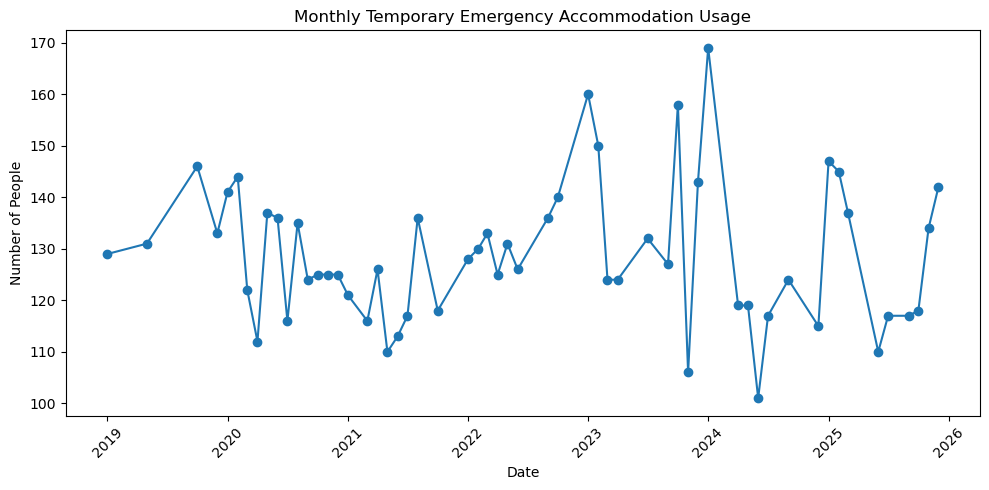

In [9]:
# Basic exploratory data analysis and monthly TEA usage plot

print("Shape:", df.shape)
print("Missing values:")
display(df.isna().sum().sort_values(ascending=False).head(20))

monthly_total = df.groupby("date")[TARGET_COUNT_COL].sum().reset_index()

plt.figure(figsize=(10, 5))
plt.plot(monthly_total["date"], monthly_total[TARGET_COUNT_COL], marker="o")
plt.title("Monthly Temporary Emergency Accommodation Usage")
plt.xlabel("Date")
plt.ylabel("Number of People")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(os.path.join(IMAGE_DIR, "monthly_tea_usage.png"), dpi=300, bbox_inches="tight")
plt.show()


In [10]:
# Feature engineering

def add_time_features(data, target_col, region_col=None):
    data = data.copy()

    if region_col:
        grouped = data.groupby(region_col, group_keys=False)
        data["lag_1"] = grouped[target_col].shift(1)
        data["lag_2"] = grouped[target_col].shift(2)
        data["rolling_3_mean"] = grouped[target_col].shift(1).rolling(3).mean()
    else:
        data["lag_1"] = data[target_col].shift(1)
        data["lag_2"] = data[target_col].shift(2)
        data["rolling_3_mean"] = data[target_col].shift(1).rolling(3).mean()

    return data

df_model = add_time_features(df, TARGET_COUNT_COL, REGION_COL)
df_model = df_model.dropna(subset=["lag_1", "lag_2", "rolling_3_mean"]).reset_index(drop=True)

print("Shape after feature engineering:", df_model.shape)
display(df_model[["date", TARGET_COUNT_COL, "lag_1", "lag_2", "rolling_3_mean"]].head())


Shape after feature engineering: (495, 28)


,date,number_of_people_who_accessed_temporary_emergency_accommodation,lag_1,lag_2,rolling_3_mean
0,2019-10-01,65,72.0,72.0,24.000000
1,2019-10-01,3,3.0,3.0,25.000000
2,2019-10-01,37,39.0,41.0,38.000000
3,2019-10-01,25,0.0,0.0,14.000000
4,2019-10-01,0,1.0,1.0,13.333333


In [11]:
# Create High/Low target variable

df_model = df_model.sort_values("time_index").reset_index(drop=True)

split_index = int(len(df_model) * 0.75)
train_df = df_model.iloc[:split_index].copy()
test_df = df_model.iloc[split_index:].copy()

pressure_threshold = train_df[TARGET_COUNT_COL].median()

train_df["homelessness_pressure"] = np.where(train_df[TARGET_COUNT_COL] > pressure_threshold, "High", "Low")
test_df["homelessness_pressure"] = np.where(test_df[TARGET_COUNT_COL] > pressure_threshold, "High", "Low")

print("Pressure threshold:", pressure_threshold)
print("Train distribution:")
print(train_df["homelessness_pressure"].value_counts())
print("Test distribution:")
print(test_df["homelessness_pressure"].value_counts())
print("Train dates:", train_df["date"].min(), "to", train_df["date"].max())
print("Test dates:", test_df["date"].min(), "to", test_df["date"].max())


Pressure threshold: 5.0
Train distribution:
homelessness_pressure
Low     187
High    184
Name: count, dtype: int64
Test distribution:
homelessness_pressure
Low     63
High    61
Name: count, dtype: int64
Train dates: 2019-10-01 00:00:00 to 2024-05-01 00:00:00
Test dates: 2024-05-01 00:00:00 to 2025-12-01 00:00:00


In [12]:
# Prepare features and preprocessing

exclude_cols = [TARGET_COUNT_COL, "homelessness_pressure", "date"]

feature_cols = [c for c in df_model.columns if c not in exclude_cols]

X_train = train_df[feature_cols].copy()
X_test = test_df[feature_cols].copy()
y_train = train_df["homelessness_pressure"].copy()
y_test = test_df["homelessness_pressure"].copy()

X_train = X_train.replace([np.inf, -np.inf], np.nan)
X_test = X_test.replace([np.inf, -np.inf], np.nan)

empty_cols = X_train.columns[X_train.isna().all()].tolist()
if empty_cols:
    print("Dropping fully empty columns:", empty_cols)
    X_train = X_train.drop(columns=empty_cols)
    X_test = X_test.drop(columns=empty_cols)

label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

categorical_cols = X_train.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
numeric_cols = X_train.select_dtypes(include=["int64", "float64", "int32", "float32"]).columns.tolist()

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_cols),
    ("cat", categorical_transformer, categorical_cols)
], remainder="drop")

print("Features:", X_train.shape[1])
print("Numeric:", numeric_cols)
print("Categorical:", categorical_cols)
print("Target classes:", list(label_encoder.classes_))


Features: 26
Numeric: ['total_adults', 'male_adults', 'female_adults', 'adults_aged_18_24', 'adults_aged_25_44', 'adults_aged_45_64', 'adults_aged_65+', 'number_of_people_who_accessed_private_emergency_accommodation', 'number_of_people_who_accessed_supported_temporary_accommodation', 'number_of_people_who_accessed_other_accommodation', 'number_of_families', 'number_of_adults_in_families', 'number_of_single_parent_families', 'number_of_dependants_in_families', 'number_of_single_adults', 'year', 'month', 'time_index', 'lag_1', 'lag_2', 'rolling_3_mean']
Categorical: ['region', 'number_of_people_with_citizenship_irish', 'number_of_people_with_citizenship_eea_uk', 'number_of_people_with_citizenship_non_eea', 'source_file']
Target classes: ['High', 'Low']


In [13]:
# Define the baseline and advanced classification models used for performance comparison.

import xgboost as xgb

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE),
    "SVM": SVC(probability=True, random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(),
    "XGBoost": xgb.XGBClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=RANDOM_STATE,
        eval_metric="logloss"
    )
}


In [14]:
# Train and compare ML models with training and testing time

results = []
trained_models = {}

for name, model in models.items():
    print(f"Training started: {name}")

    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    train_start_time = time.time()
    pipe.fit(X_train, y_train_encoded)
    train_end_time = time.time()
    training_time = train_end_time - train_start_time

    trained_models[name] = pipe

    test_start_time = time.time()
    y_pred = pipe.predict(X_test)

    if hasattr(pipe.named_steps["model"], "predict_proba"):
        y_proba = pipe.predict_proba(X_test)[:, 1]
    else:
        y_proba = None

    test_end_time = time.time()
    testing_time = test_end_time - test_start_time

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_encoded, y_pred),
        "Precision": precision_score(y_test_encoded, y_pred, zero_division=0),
        "Recall": recall_score(y_test_encoded, y_pred, zero_division=0),
        "F1-score": f1_score(y_test_encoded, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test_encoded, y_proba) if y_proba is not None else np.nan,
        "Training Time (seconds)": training_time,
        "Testing Time (seconds)": testing_time
    })

    print(
        f"Training completed: {name} | "
        f"Training Time: {training_time:.4f} seconds | "
        f"Testing Time: {testing_time:.4f} seconds"
    )

results_df = pd.DataFrame(results)

# Sort by F1-score first, then ROC-AUC, then testing time.
results_df = results_df.sort_values(
    by=["F1-score", "ROC-AUC", "Testing Time (seconds)"],
    ascending=[False, False, True]
).reset_index(drop=True)

display(results_df)

# Save model-comparison results for the artefact folder.
results_df.to_csv(os.path.join(OUTPUT_DIR, "model_comparison_results.csv"), index=False)

# Separate model-selection summaries.
best_f1_score = results_df["F1-score"].max()
best_f1_models = results_df[results_df["F1-score"] == best_f1_score]["Model"].tolist()

best_roc_auc_model = results_df.sort_values("ROC-AUC", ascending=False).iloc[0]["Model"]
fastest_training_model = results_df.sort_values("Training Time (seconds)").iloc[0]["Model"]
fastest_testing_model = results_df.sort_values("Testing Time (seconds)").iloc[0]["Model"]

# Final selected model for this study.
final_model_name = "SVM"
final_model = trained_models[final_model_name]

print("Models with highest F1-score:", best_f1_models)
print("Best ROC-AUC model:", best_roc_auc_model)
print("Fastest training model:", fastest_training_model)
print("Fastest testing model:", fastest_testing_model)
print("Final selected model:", final_model_name)


Training started: Logistic Regression
Training completed: Logistic Regression | Training Time: 0.1679 seconds | Testing Time: 0.0310 seconds
Training started: Decision Tree
Training completed: Decision Tree | Training Time: 0.0515 seconds | Testing Time: 0.0297 seconds
Training started: Random Forest
Training completed: Random Forest | Training Time: 0.3084 seconds | Testing Time: 0.0390 seconds
Training started: SVM
Training completed: SVM | Training Time: 0.0522 seconds | Testing Time: 0.0330 seconds
Training started: KNN
Training completed: KNN | Training Time: 0.0141 seconds | Testing Time: 0.0184 seconds
Training started: XGBoost
Training completed: XGBoost | Training Time: 0.6641 seconds | Testing Time: 0.0200 seconds


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,Training Time (seconds),Testing Time (seconds)
0,Random Forest,0.959677,0.939394,0.984127,0.961240,0.988681,0.308393,0.038957
1,SVM,0.959677,0.939394,0.984127,0.961240,0.983346,0.052207,0.032975
2,KNN,0.959677,0.939394,0.984127,0.961240,0.980224,0.014067,0.018417
3,XGBoost,0.959677,0.953125,0.968254,0.960630,0.995316,0.664088,0.020000
4,Logistic Regression,0.951613,0.925373,0.984127,0.953846,0.973458,0.167923,0.031037
5,Decision Tree,0.951613,0.938462,0.968254,0.953125,0.951340,0.051488,0.029706


Models with highest F1-score: ['Random Forest', 'SVM', 'KNN']
Best ROC-AUC model: XGBoost
Fastest training model: KNN
Fastest testing model: KNN
Final selected model: SVM



Model: Logistic Regression
Confusion Matrix:
[[56  5]
 [ 1 62]]


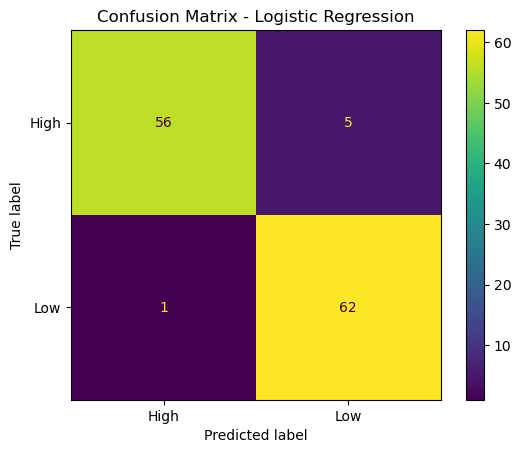


Model: Decision Tree
Confusion Matrix:
[[57  4]
 [ 2 61]]


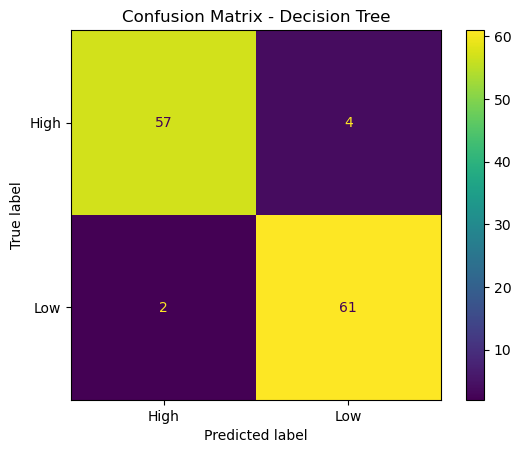


Model: Random Forest
Confusion Matrix:
[[57  4]
 [ 1 62]]


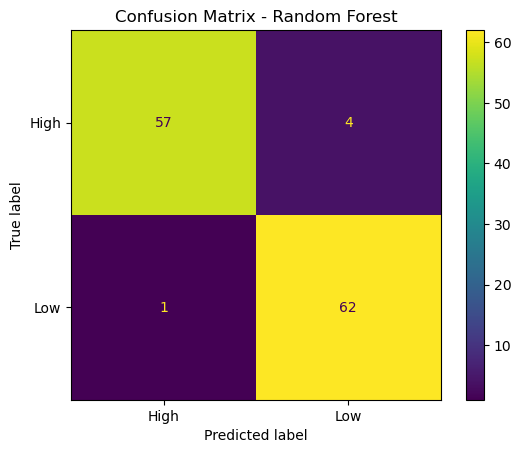


Model: SVM
Confusion Matrix:
[[57  4]
 [ 1 62]]


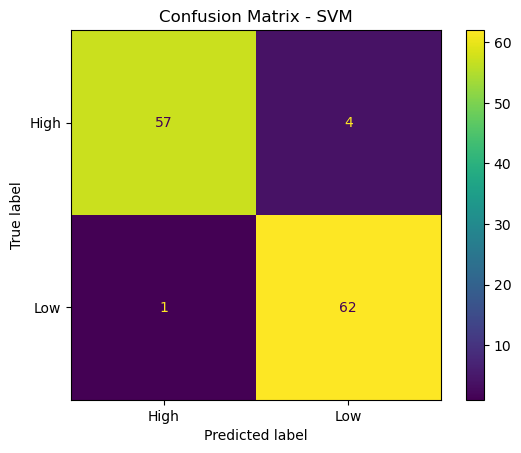


Model: KNN
Confusion Matrix:
[[57  4]
 [ 1 62]]


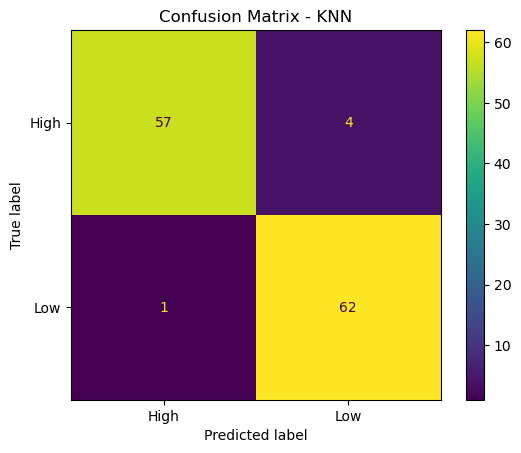


Model: XGBoost
Confusion Matrix:
[[58  3]
 [ 2 61]]


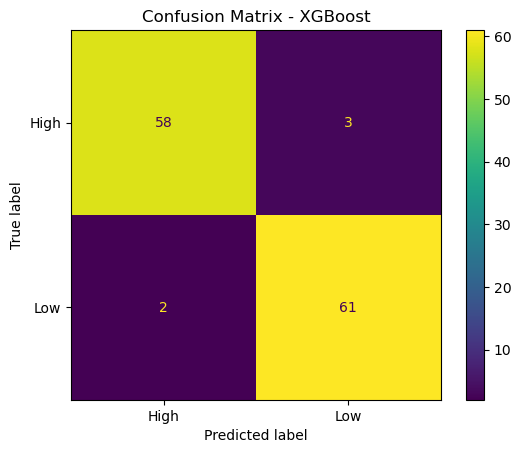

,Model,True High predicted High,True High predicted Low,True Low predicted High,True Low predicted Low
0,Logistic Regression,56,5,1,62
1,Decision Tree,57,4,2,61
2,Random Forest,57,4,1,62
3,SVM,57,4,1,62
4,KNN,57,4,1,62
5,XGBoost,58,3,2,61


In [15]:
# Confusion matrix for all machine learning models

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

confusion_matrix_summary = []

for model_name, model in trained_models.items():
    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test_encoded, y_pred)

    print("\nModel:", model_name)
    print("Confusion Matrix:")
    print(cm)

    # Store values for summary table.
    confusion_matrix_summary.append({
        "Model": model_name,
        "True High predicted High": cm[0, 0],
        "True High predicted Low": cm[0, 1],
        "True Low predicted High": cm[1, 0],
        "True Low predicted Low": cm[1, 1]
    })

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=label_encoder.classes_
    )

    disp.plot()
    plt.title(f"Confusion Matrix - {model_name}")
    safe_model_name = model_name.lower().replace(" ", "_")
    plt.savefig(
        os.path.join(IMAGE_DIR, f"confusion_matrix_{safe_model_name}.png"),
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

confusion_matrix_df = pd.DataFrame(confusion_matrix_summary)
display(confusion_matrix_df)

# Save confusion matrix summary table for the artefact folder.
confusion_matrix_df.to_csv(os.path.join(OUTPUT_DIR, "confusion_matrix_summary.csv"), index=False)


In [16]:
# Check whether Random Forest, SVM and KNN have identical confusion matrices

rf_pred = trained_models["Random Forest"].predict(X_test)
svm_pred = trained_models["SVM"].predict(X_test)
knn_pred = trained_models["KNN"].predict(X_test)

rf_cm = confusion_matrix(y_test_encoded, rf_pred)
svm_cm = confusion_matrix(y_test_encoded, svm_pred)
knn_cm = confusion_matrix(y_test_encoded, knn_pred)

print("Random Forest Confusion Matrix:")
print(rf_cm)

print("\nSVM Confusion Matrix:")
print(svm_cm)

print("\nKNN Confusion Matrix:")
print(knn_cm)

print("\nRandom Forest and SVM same confusion matrix:", np.array_equal(rf_cm, svm_cm))
print("Random Forest and KNN same confusion matrix:", np.array_equal(rf_cm, knn_cm))
print("SVM and KNN same confusion matrix:", np.array_equal(svm_cm, knn_cm))

Random Forest Confusion Matrix:
[[57  4]
 [ 1 62]]

SVM Confusion Matrix:
[[57  4]
 [ 1 62]]

KNN Confusion Matrix:
[[57  4]
 [ 1 62]]

Random Forest and SVM same confusion matrix: True
Random Forest and KNN same confusion matrix: True
SVM and KNN same confusion matrix: True


In [17]:
# TimeSeries cross-validation with execution time

tscv = TimeSeriesSplit(n_splits=5)
cv_results = []

for name, model in models.items():
    print(f"Cross-validation started: {name}")
    cv_start_time = time.time()

    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    try:
        scores = cross_val_score(
            pipe,
            X_train,
            y_train_encoded,
            cv=tscv,
            scoring="f1",
            error_score=np.nan
        )

        cv_time = time.time() - cv_start_time

        cv_results.append({
            "Model": name,
            "CV F1 Mean": np.nanmean(scores),
            "CV F1 Std": np.nanstd(scores),
            "CV Time (seconds)": cv_time
        })

        print(f"Cross-validation completed: {name} | Time: {cv_time:.4f} seconds")

    except Exception as e:
        cv_time = time.time() - cv_start_time
        print(f"{name} CV failed:", e)
        cv_results.append({
            "Model": name,
            "CV F1 Mean": np.nan,
            "CV F1 Std": np.nan,
            "CV Time (seconds)": cv_time
        })

cv_results_df = pd.DataFrame(cv_results).sort_values("CV F1 Mean", ascending=False).reset_index(drop=True)
display(cv_results_df)


Cross-validation started: Logistic Regression
Cross-validation completed: Logistic Regression | Time: 0.2484 seconds
Cross-validation started: Decision Tree
Cross-validation completed: Decision Tree | Time: 0.2163 seconds
Cross-validation started: Random Forest
Cross-validation completed: Random Forest | Time: 0.8574 seconds
Cross-validation started: SVM
Cross-validation completed: SVM | Time: 0.1973 seconds
Cross-validation started: KNN
Cross-validation completed: KNN | Time: 0.5021 seconds
Cross-validation started: XGBoost
Cross-validation completed: XGBoost | Time: 0.3170 seconds


,Model,CV F1 Mean,CV F1 Std,CV Time (seconds)
0,XGBoost,0.984489,0.023484,0.316978
1,Logistic Regression,0.980982,0.024713,0.248384
2,Decision Tree,0.977352,0.027852,0.216309
3,Random Forest,0.974548,0.031938,0.857423
4,SVM,0.967087,0.035982,0.197343
5,KNN,0.942065,0.064896,0.502139


In [18]:
# Improvement over baseline model

baseline_model_name = "Logistic Regression"
final_model_name = "SVM"

final_model_row = results_df[results_df["Model"] == final_model_name].iloc[0]
baseline = results_df[results_df["Model"] == baseline_model_name].iloc[0]

improvement_df = pd.DataFrame({
    "Comparison": ["Final selected model", "Baseline model", "Improvement"],
    "Model": [
        final_model_name,
        baseline_model_name,
        f"{final_model_name} - {baseline_model_name}"
    ],
    "F1-score": [
        final_model_row["F1-score"],
        baseline["F1-score"],
        final_model_row["F1-score"] - baseline["F1-score"]
    ],
    "ROC-AUC": [
        final_model_row["ROC-AUC"],
        baseline["ROC-AUC"],
        final_model_row["ROC-AUC"] - baseline["ROC-AUC"]
    ]
})

display(improvement_df)

,Comparison,Model,F1-score,ROC-AUC
0,Final selected model,SVM,0.961240,0.983346
1,Baseline model,Logistic Regression,0.953846,0.973458
2,Improvement,SVM - Logistic Regression,0.007394,0.009888


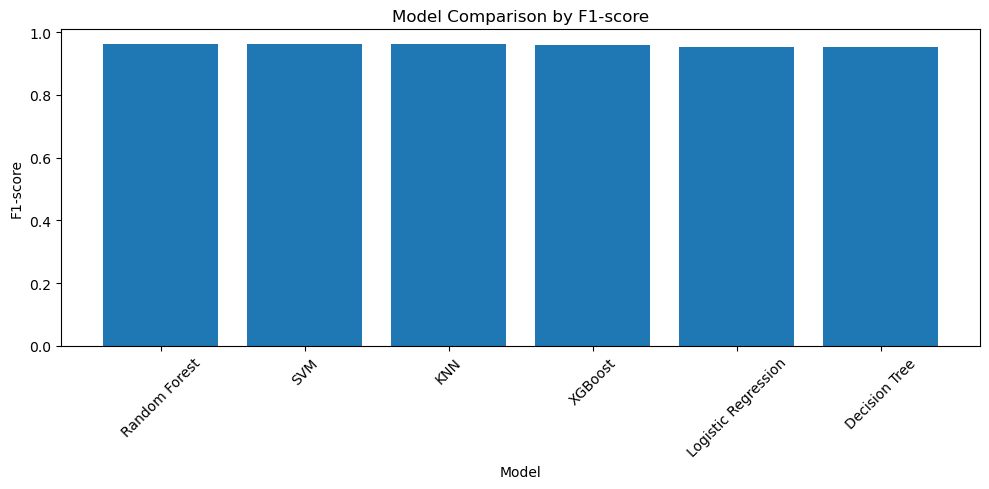

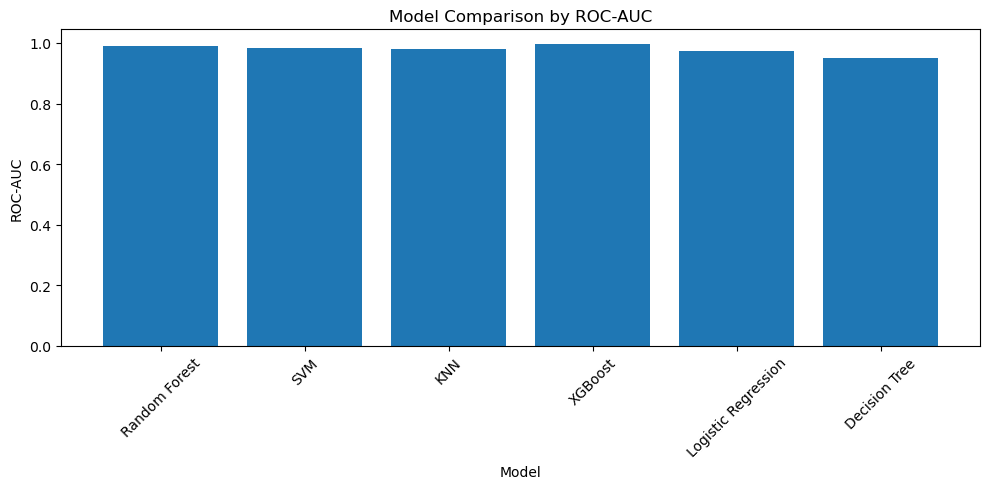

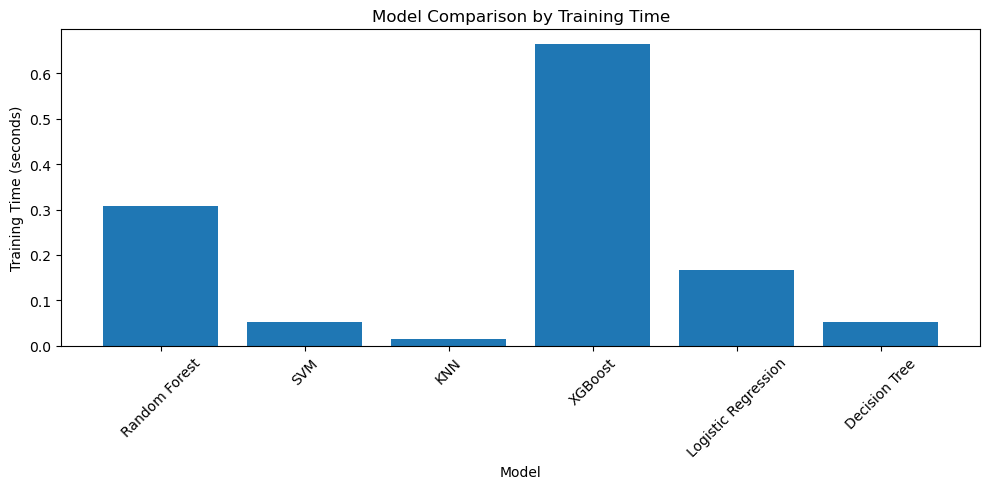

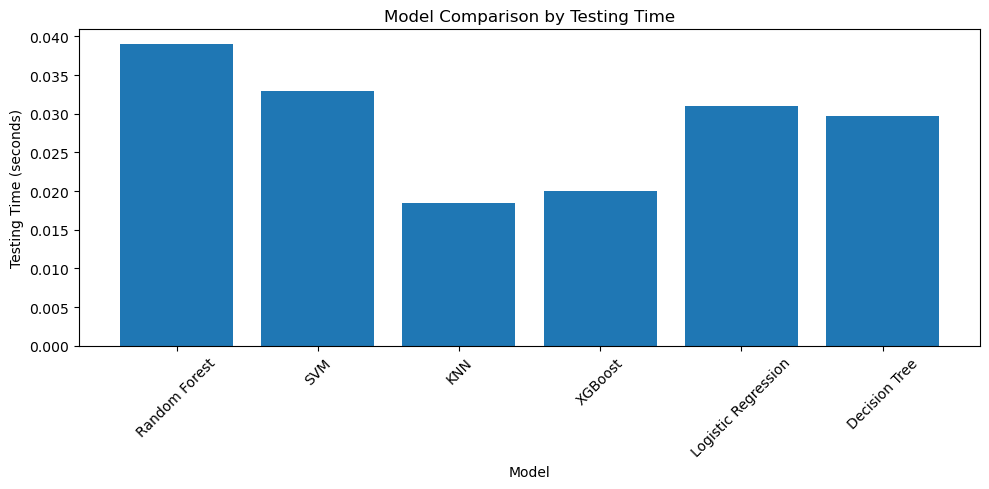

In [19]:
# Model comparison plots saved as image files

plt.figure(figsize=(10, 5))
plt.bar(results_df["Model"], results_df["F1-score"])
plt.title("Model Comparison by F1-score")
plt.xlabel("Model")
plt.ylabel("F1-score")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(os.path.join(IMAGE_DIR, "f1_score_comparison.png"), dpi=300, bbox_inches="tight")
plt.show()

plt.figure(figsize=(10, 5))
plt.bar(results_df["Model"], results_df["ROC-AUC"])
plt.title("Model Comparison by ROC-AUC")
plt.xlabel("Model")
plt.ylabel("ROC-AUC")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(os.path.join(IMAGE_DIR, "roc_auc_comparison.png"), dpi=300, bbox_inches="tight")
plt.show()

plt.figure(figsize=(10, 5))
plt.bar(results_df["Model"], results_df["Training Time (seconds)"])
plt.title("Model Comparison by Training Time")
plt.xlabel("Model")
plt.ylabel("Training Time (seconds)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(os.path.join(IMAGE_DIR, "training_time_comparison.png"), dpi=300, bbox_inches="tight")
plt.show()

plt.figure(figsize=(10, 5))
plt.bar(results_df["Model"], results_df["Testing Time (seconds)"])
plt.title("Model Comparison by Testing Time")
plt.xlabel("Model")
plt.ylabel("Testing Time (seconds)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(os.path.join(IMAGE_DIR, "testing_time_comparison.png"), dpi=300, bbox_inches="tight")
plt.show()


Final selected model: SVM
SVM was selected as the final model because it provides a balanced trade-off between F1-score, ROC-AUC, training time, testing time, and interpretability.
              precision    recall  f1-score   support

        High       0.98      0.93      0.96        61
         Low       0.94      0.98      0.96        63

    accuracy                           0.96       124
   macro avg       0.96      0.96      0.96       124
weighted avg       0.96      0.96      0.96       124



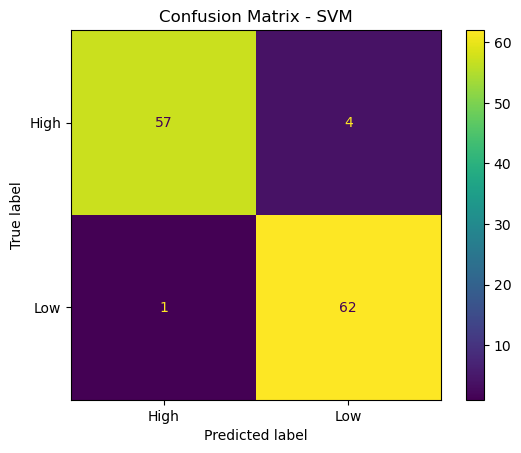

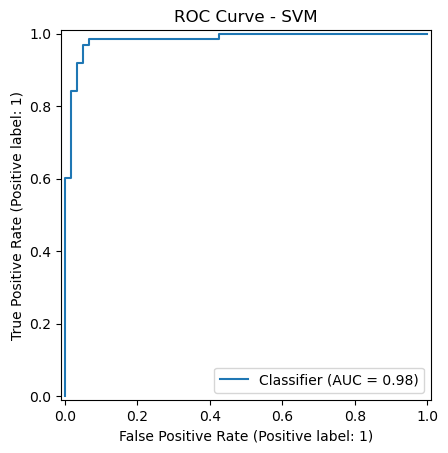

In [20]:
# Final selected SVM model evaluation

final_model_name = "SVM"
final_model = trained_models[final_model_name]

print("Final selected model:", final_model_name)
print(
    "SVM was selected as the final model because it provides a balanced trade-off "
    "between F1-score, ROC-AUC, training time, testing time, and interpretability."
)

y_pred_final = final_model.predict(X_test)

print(classification_report(
    y_test_encoded,
    y_pred_final,
    target_names=label_encoder.classes_
))

cm = confusion_matrix(y_test_encoded, y_pred_final)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
)
disp.plot()
plt.title(f"Confusion Matrix - {final_model_name}")
plt.savefig(os.path.join(IMAGE_DIR, "svm_confusion_matrix.png"), dpi=300, bbox_inches="tight")
plt.show()

if hasattr(final_model.named_steps["model"], "predict_proba"):
    y_proba_final = final_model.predict_proba(X_test)[:, 1]
    RocCurveDisplay.from_predictions(y_test_encoded, y_proba_final)
    plt.title(f"ROC Curve - {final_model_name}")
    plt.savefig(os.path.join(IMAGE_DIR, "svm_roc_curve.png"), dpi=300, bbox_inches="tight")
    plt.show()


Feature importance model: XGBoost


,Feature,Importance
18,num__lag_1,0.737455
25,cat__region_North-East,0.036415
3,num__adults_aged_18_24,0.033656
8,num__number_of_people_who_accessed_supported_t...,0.033611
305,cat__source_file_homelessness-report-december-...,0.023246
5,num__adults_aged_45_64,0.018187
19,num__lag_2,0.013663
2,num__female_adults,0.012762
6,num__adults_aged_65+,0.012605
20,num__rolling_3_mean,0.012079


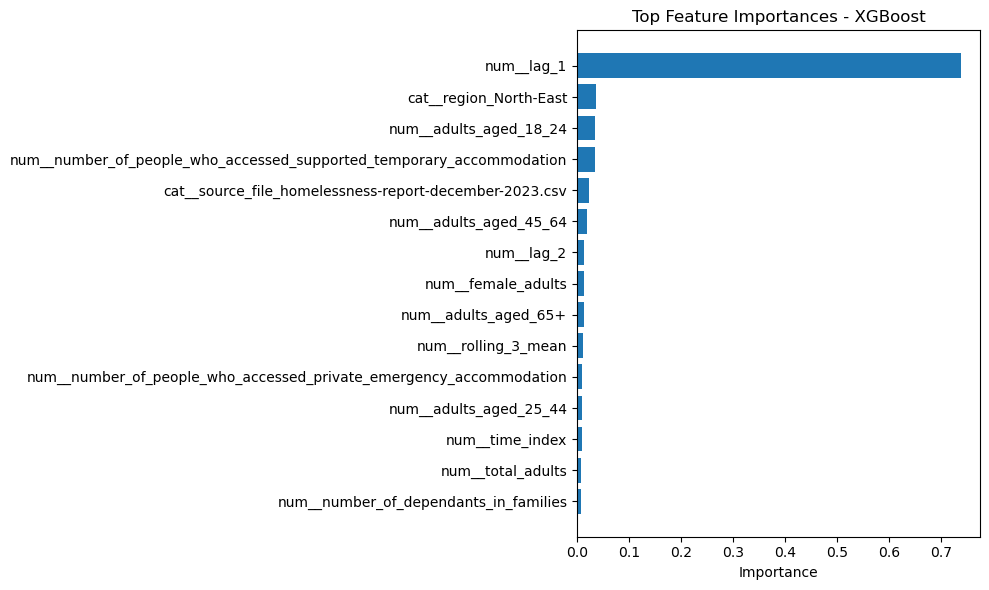

In [21]:
# Feature importance for the best tree-based model

try:
    tree_model_names = [m for m in ["Decision Tree", "Random Forest", "XGBoost"] if m in trained_models]

    if len(tree_model_names) == 0:
        print("No tree-based model found for feature importance.")
    else:
        # Select the best tree-based model by ROC-AUC because ROC-AUC measures class separation.
        tree_results = (
            results_df[results_df["Model"].isin(tree_model_names)]
            .sort_values("ROC-AUC", ascending=False)
            .reset_index(drop=True)
        )

        best_tree_model_name = tree_results.iloc[0]["Model"]
        best_tree_model = trained_models[best_tree_model_name]

        fitted_preprocessor = best_tree_model.named_steps["preprocessor"]
        fitted_classifier = best_tree_model.named_steps["model"]
        feature_names = fitted_preprocessor.get_feature_names_out()

        print("Feature importance model:", best_tree_model_name)

        if hasattr(fitted_classifier, "feature_importances_"):
            importance_df = pd.DataFrame({
                "Feature": feature_names,
                "Importance": fitted_classifier.feature_importances_
            }).sort_values("Importance", ascending=False).head(15)

            display(importance_df)
            importance_df.to_csv(os.path.join(OUTPUT_DIR, "tree_feature_importance.csv"), index=False)

            plt.figure(figsize=(10, 6))
            plt.barh(importance_df["Feature"][::-1], importance_df["Importance"][::-1])
            plt.title(f"Top Feature Importances - {best_tree_model_name}")
            plt.xlabel("Importance")
            plt.tight_layout()
            plt.savefig(os.path.join(IMAGE_DIR, "tree_feature_importance.png"), dpi=300, bbox_inches="tight")
            plt.show()
        else:
            print("Selected tree-based model does not provide built-in feature importance.")

except Exception as e:
    print("Feature importance failed:", e)


## SHAP Global Explainability

SHAP is used for the best-performing tree-based model.  
This is suitable for models such as Decision Tree, Random Forest, and XGBoost.  
The SHAP summary plot explains overall feature importance across the test dataset.


SHAP explanation model: XGBoost


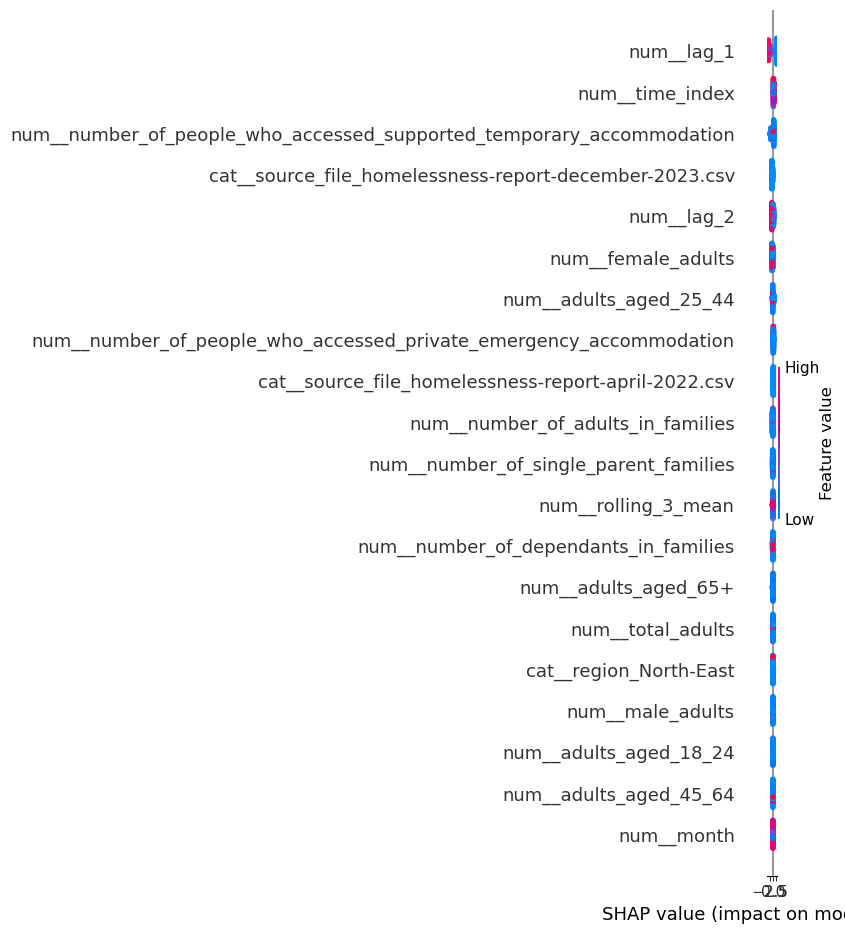

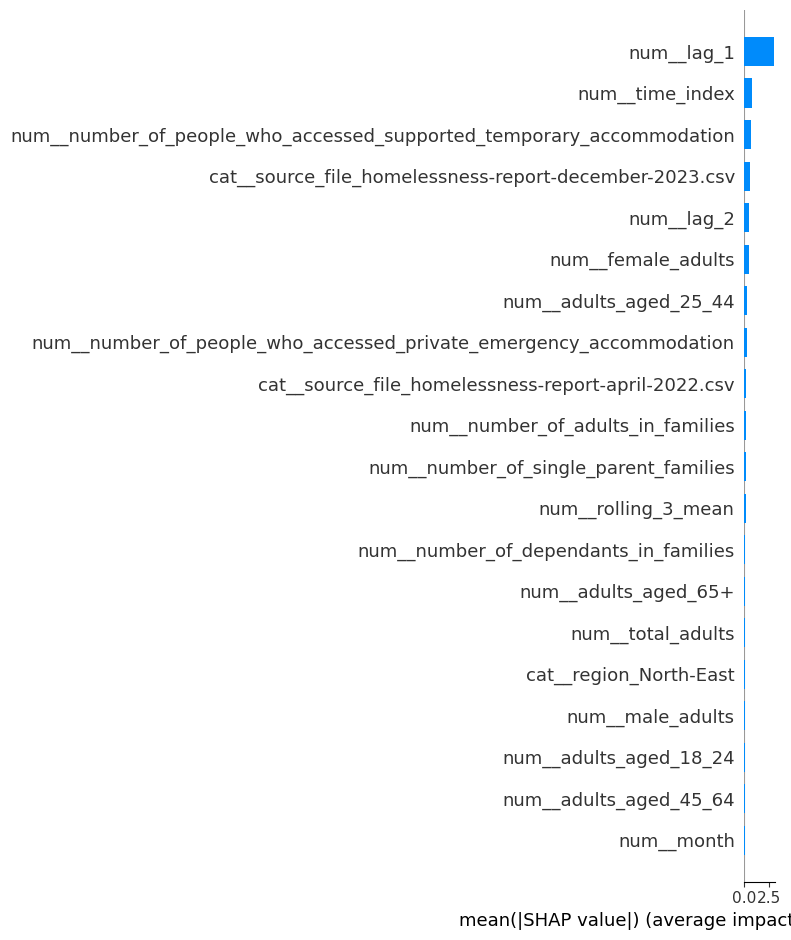

In [22]:
# SHAP global explainability for the best tree-based model

try:
    import shap
    SHAP_AVAILABLE = True
except Exception:
    SHAP_AVAILABLE = False
    print("SHAP is not installed. Run this command in a new cell, then restart kernel:")
    print("pip install shap")

required_variables = [
    "results_df",
    "trained_models",
    "X_test"
]

missing_variables = [var for var in required_variables if var not in globals()]

if missing_variables:
    print("Please run all previous notebook cells before running SHAP.")
    print("Missing variables:", missing_variables)
    print("In Jupyter, use: Kernel -> Restart & Run All")
elif not SHAP_AVAILABLE:
    print("SHAP is unavailable. Install SHAP and run the notebook again.")
else:
    try:
        tree_model_names = [m for m in ["Decision Tree", "Random Forest", "XGBoost"] if m in trained_models]

        if len(tree_model_names) == 0:
            print("No tree-based model found for SHAP.")
        else:
            # Select the best tree-based model by ROC-AUC.
            tree_results = (
                results_df[results_df["Model"].isin(tree_model_names)]
                .sort_values("ROC-AUC", ascending=False)
                .reset_index(drop=True)
            )

            shap_model_name = tree_results.iloc[0]["Model"]
            shap_model = trained_models[shap_model_name]

            print("SHAP explanation model:", shap_model_name)

            # Transform test data using the fitted preprocessor.
            X_test_processed = shap_model.named_steps["preprocessor"].transform(X_test)

            if hasattr(X_test_processed, "toarray"):
                X_test_processed = X_test_processed.toarray()

            feature_names = shap_model.named_steps["preprocessor"].get_feature_names_out()
            model_only = shap_model.named_steps["model"]

            # Create SHAP TreeExplainer.
            explainer = shap.TreeExplainer(model_only)
            shap_values = explainer.shap_values(X_test_processed)

            # Handle binary classification output format.
            if isinstance(shap_values, list):
                values_to_plot = shap_values[1]
            elif len(getattr(shap_values, "shape", [])) == 3:
                values_to_plot = shap_values[:, :, 1]
            else:
                values_to_plot = shap_values

            # SHAP summary plot.
            shap.summary_plot(
                values_to_plot,
                X_test_processed,
                feature_names=feature_names,
                show=False
            )
            plt.tight_layout()
            plt.savefig(os.path.join(IMAGE_DIR, "shap_summary_plot.png"), dpi=300, bbox_inches="tight")
            plt.show()

            # SHAP bar plot for easier report screenshot.
            shap.summary_plot(
                values_to_plot,
                X_test_processed,
                feature_names=feature_names,
                plot_type="bar",
                show=False
            )
            plt.tight_layout()
            plt.savefig(os.path.join(IMAGE_DIR, "shap_feature_importance_bar.png"), dpi=300, bbox_inches="tight")
            plt.show()

    except Exception as e:
        print("SHAP visualisation failed.")
        print("Error:", e)


## LIME Local Explainability

LIME is used to explain one selected prediction from the best overall model.  
This is useful when the best model is non-tree-based, such as SVM.  
The output shows prediction probability and a local feature-contribution chart.


LIME visualisation model: SVM
Selected test instance: 0
Predicted class: Low
Prediction probabilities:
High: 0.0135
Low: 0.9865


LIME feature contributions:


,Feature,Contribution
0,cat__number_of_people_with_citizenship_non_eea...,0.213378
1,cat__region_North-West <= 0.00,0.197009
2,cat__number_of_people_with_citizenship_non_eea...,-0.164945
3,cat__number_of_people_with_citizenship_irish_2...,-0.153119
4,cat__number_of_people_with_citizenship_eea_uk_...,0.151211
5,cat__number_of_people_with_citizenship_irish_3...,0.133192
6,cat__number_of_people_with_citizenship_eea_uk_...,0.131596
7,cat__number_of_people_with_citizenship_irish_4...,0.118466
8,cat__number_of_people_with_citizenship_irish_3...,0.109570
9,cat__number_of_people_with_citizenship_eea_uk_...,0.103997


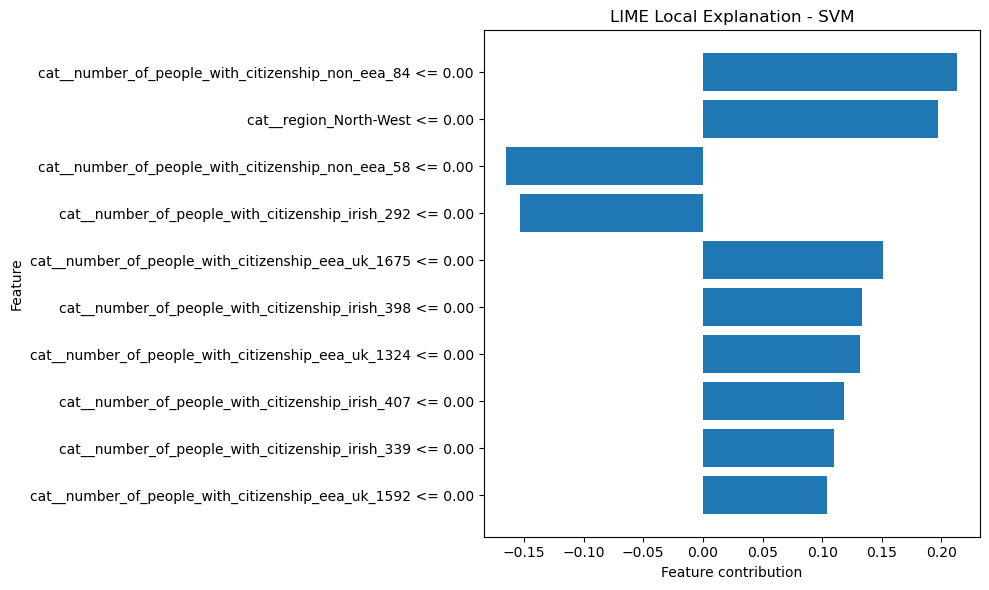

In [23]:
# LIME visualisation for selected SVM prediction

try:
    from lime.lime_tabular import LimeTabularExplainer
    LIME_AVAILABLE = True
except Exception:
    LIME_AVAILABLE = False
    print("LIME is not installed. Run this command in a new cell, then restart kernel:")
    print("pip install lime")

required_variables = [
    "results_df",
    "trained_models",
    "X_train",
    "X_test",
    "label_encoder",
    "RANDOM_STATE"
]

missing_variables = [var for var in required_variables if var not in globals()]

if missing_variables:
    print("Please run all previous notebook cells before running LIME visualisation.")
    print("Missing variables:", missing_variables)
    print("In Jupyter, use: Kernel -> Restart & Run All")

elif not LIME_AVAILABLE:
    print("LIME is unavailable. Install LIME and run the notebook again.")

else:
    try:
        # Select SVM as the final model for local explanation.
        final_model_name = "SVM"

        if final_model_name not in trained_models:
            raise ValueError(f"{final_model_name} model is not available in trained_models.")

        final_model = trained_models[final_model_name]

        print("LIME visualisation model:", final_model_name)

        # Transform train and test data using the fitted SVM preprocessor.
        X_train_processed = final_model.named_steps["preprocessor"].transform(X_train)
        X_test_processed = final_model.named_steps["preprocessor"].transform(X_test)

        if hasattr(X_train_processed, "toarray"):
            X_train_processed = X_train_processed.toarray()
            X_test_processed = X_test_processed.toarray()

        feature_names = final_model.named_steps["preprocessor"].get_feature_names_out()

        lime_explainer = LimeTabularExplainer(
            training_data=X_train_processed,
            feature_names=feature_names,
            class_names=list(label_encoder.classes_),
            mode="classification",
            discretize_continuous=True,
            random_state=RANDOM_STATE
        )

        # Select one test record for local explanation.
        instance_index = 0

        predicted_class_numeric = final_model.predict(X_test.iloc[[instance_index]])[0]
        predicted_class_label = label_encoder.inverse_transform([predicted_class_numeric])[0]

        prediction_probabilities = final_model.predict_proba(X_test.iloc[[instance_index]])[0]

        print("Selected test instance:", instance_index)
        print("Predicted class:", predicted_class_label)
        print("Prediction probabilities:")

        for class_name, probability in zip(label_encoder.classes_, prediction_probabilities):
            print(f"{class_name}: {probability:.4f}")

        lime_exp = lime_explainer.explain_instance(
            data_row=X_test_processed[instance_index],
            predict_fn=final_model.named_steps["model"].predict_proba,
            num_features=10
        )

        # Interactive notebook visualisation.
        lime_exp.show_in_notebook(show_table=True, show_all=False)

        # Save interactive LIME explanation as HTML.
        lime_exp.save_to_file(os.path.join(OUTPUT_DIR, "lime_svm_explanation.html"))

        # Table output.
        lime_features = lime_exp.as_list()
        lime_df = pd.DataFrame(lime_features, columns=["Feature", "Contribution"])

        print("LIME feature contributions:")
        display(lime_df)
        lime_df.to_csv(os.path.join(OUTPUT_DIR, "lime_svm_feature_contributions.csv"), index=False)

        # Static chart output for report screenshot.
        plt.figure(figsize=(10, 6))
        plt.barh(lime_df["Feature"][::-1], lime_df["Contribution"][::-1])
        plt.title(f"LIME Local Explanation - {final_model_name}")
        plt.xlabel("Feature contribution")
        plt.ylabel("Feature")
        plt.tight_layout()
        plt.savefig(os.path.join(IMAGE_DIR, "lime_svm_explanation.png"), dpi=300, bbox_inches="tight")
        plt.show()

    except Exception as e:
        print("LIME visualisation failed.")
        print("Error:", e)


## Time Calculation Summary

This cell calculates total notebook runtime and compares fastest/best models.

In [24]:
# Final total notebook execution time summary

notebook_end_time = time.time()
total_time_seconds = notebook_end_time - notebook_start_time
total_time_minutes = total_time_seconds / 60

print("Total notebook execution time:")
print(f"{total_time_seconds:.2f} seconds")
print(f"{total_time_minutes:.2f} minutes")

print("\nModels with highest F1-score:")
display(results_df[results_df["F1-score"] == results_df["F1-score"].max()])

print("\nBest model by ROC-AUC:")
display(results_df.sort_values("ROC-AUC", ascending=False).head(1))

print("\nFastest model by training time:")
display(results_df.sort_values("Training Time (seconds)").head(1))

print("\nFastest model by testing time:")
display(results_df.sort_values("Testing Time (seconds)").head(1))

print("\nFinal selected model:")
display(results_df[results_df["Model"] == "SVM"])

print("\nSaved output files:")
for root, dirs, files in os.walk(OUTPUT_DIR):
    for file in files:
        print(os.path.join(root, file))


Total notebook execution time:
132.78 seconds
2.21 minutes

Models with highest F1-score:


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,Training Time (seconds),Testing Time (seconds)
0,Random Forest,0.959677,0.939394,0.984127,0.96124,0.988681,0.308393,0.038957
1,SVM,0.959677,0.939394,0.984127,0.96124,0.983346,0.052207,0.032975
2,KNN,0.959677,0.939394,0.984127,0.96124,0.980224,0.014067,0.018417



Best model by ROC-AUC:


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,Training Time (seconds),Testing Time (seconds)
3,XGBoost,0.959677,0.953125,0.968254,0.96063,0.995316,0.664088,0.02



Fastest model by training time:


...


Fastest model by testing time:


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,Training Time (seconds),Testing Time (seconds)
2,KNN,0.959677,0.939394,0.984127,0.96124,0.980224,0.014067,0.018417



Final selected model:


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,Training Time (seconds),Testing Time (seconds)
1,SVM,0.959677,0.939394,0.984127,0.96124,0.983346,0.052207,0.032975



Saved output files:
outputs\confusion_matrix_summary.csv
outputs\lime_svm_explanation.html
outputs\lime_svm_feature_contributions.csv
outputs\model_comparison_results.csv
outputs\tree_feature_importance.csv
outputs\images\confusion_matrix_decision_tree.png
outputs\images\confusion_matrix_knn.png
outputs\images\confusion_matrix_logistic_regression.png
outputs\images\confusion_matrix_random_forest.png
outputs\images\confusion_matrix_svm.png
outputs\images\confusion_matrix_xgboost.png
outputs\images\f1_score_comparison.png
outputs\images\lime_svm_explanation.png
outputs\images\monthly_tea_usage.png
outputs\images\roc_auc_comparison.png
outputs\images\shap_feature_importance_bar.png
outputs\images\shap_summary_plot.png
outputs\images\svm_confusion_matrix.png
outputs\images\svm_roc_curve.png
outputs\images\testing_time_comparison.png
outputs\images\training_time_comparison.png
outputs\images\tree_feature_importance.png
